# histogram plotting

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

plt.style.use('fivethirtyeight') # Use plt.style.available to see more styles
sns.set()
sns.set_context("talk")
%matplotlib inline

In [4]:
df = pd.read_csv('ComputerSales.csv')
df.head()

,Sale ID,Contact,Sex,Age,State,Product ID,Product Type,Sale Price,Profit,Lead,Month,Year
0,1,Paul Thomas,M,43,OH,M01-F0024,Desktop,479.99,143.39,Website,January,2018
1,2,Margo Simms,F,37,WV,GT13-0024,Desktop,1249.99,230.89,Flyer 4,January,2018
2,3,Sam Stine,M,26,PA,I3670,Desktop,649.99,118.64,Website,February,2018
3,4,Moe Eggert,M,35,PA,I3593,Laptop,399.99,72.09,Website,March,2018
4,5,Jessica Elk,F,55,PA,15M-ED,Laptop,699.99,98.09,Flyer 4,March,2018


C:\Users\Alon\anaconda3\lib\site-packages\seaborn\distributions.py:2557: FutureWarning: `distplot` is a deprecated function and will be removed in a future version. Please adapt your code to use either `displot` (a figure-level function with similar flexibility) or `histplot` (an axes-level function for histograms).
  warnings.warn(msg, FutureWarning)


Text(0.5, 1.0, 'Count of Each Age')

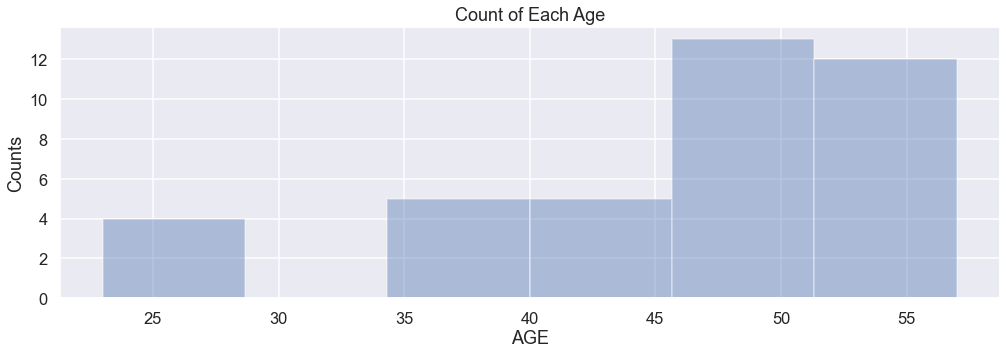

In [5]:
# distplot
plt.figure(figsize=(15, 5))
ax = sns.distplot(df['Age'], kde=False)
ax.set_xlabel('AGE')
ax.set_ylabel('Counts')
ax.set_title('Count of Each Age')

In [ ]:
df['Age'].value_counts()

In [ ]:
df['Age'].value_counts().sort_index()

In [ ]:
# subplot rug=True
plt.figure(figsize=(15, 5))
plt.subplot(1,2,1)
ax = sns.distplot(df['Age'], kde=False, rug=True)
ax.set_xlabel('AGE')
ax.set_ylabel('Counts')
ax.set_title('Count of Each Age')
plt.subplot(122)
ax = sns.distplot(df['Profit'], kde=False)
ax.set_xlabel('PROFIT')
ax.set_ylabel('Counts')
ax.set_title('Count of Each Profit')

In [ ]:
plt.figure(figsize=(15,5))
ax2 = plt.subplot(122)
sns.distplot(df['Age'], kde=False, rug=True, ax=ax2)
ax1 = plt.subplot(121)
sns.distplot(df['Profit'], kde=False, rug=True, ax=ax1)

# Kernels

 Kernel density function(not exactly same as gussian kernel)
$$\Large
K_{\alpha}(x, z) = \frac{1}{\sqrt{\pi}}e^{-\frac{(x-z)^2}{\alpha}}
$$

In [ ]:
# define K
def k_func(alpha, x, z):
    cofficient = 1 / np.sqrt(np.pi)
    y = np.exp(-(x-z)**2/alpha)
    return cofficient * y

In [ ]:
# poll
# plot kernel function at z=5
z = 5
alpha = 0.5
x_lst = np.linspace(-5, 10, 500)
k_alpha = [k_func(alpha, x, z) for x in x_lst]
plt.plot(x_lst, k_alpha)

In [ ]:
# plot two kernel functions at 3 and 5
k_alpha1 = [k_func(alpha, x, 3) for x in x_lst]
k_alpha2 = [k_func(alpha, x, 5) for x in x_lst]
plt.plot(x_lst, k_alpha1, x_lst, k_alpha2)

In [ ]:
type(k_alpha1)

In [ ]:
# a more convinient way
k_alpha3 = k_func(alpha, x_lst, 3)
k_alpha4 = k_func(alpha, x_lst, 5)
plt.plot(x_lst, k_alpha3, x_lst, k_alpha4)

In [ ]:
type(k_alpha3)

In [ ]:
# sum of kernel function(2 centers)
k2centers = (np.array(k_alpha1) + np.array(k_alpha2)) / 2
plt.plot(x_lst, k2centers)

In [ ]:
k2centers2 = (k_alpha3 + k_alpha4) / 2
plt.plot(x_lst, k2centers2)

In [ ]:
# displot with kernel function again
ax = sns.distplot(df['Profit'])
#notice we removed kde=False

In [ ]:
# plot similar curve using k_func
x_lst = np.linspace(0, 300, 1000)
profit = df['Profit'].values
display(type(profit))
k_profit = np.zeros(1000)
alpha = 500

for z in profit:
    k_current = k_func(alpha, x_lst, z)
    k_profit += k_current
    
k_profit = k_profit / len(df)
plt.plot(x_lst, k_profit)

In [ ]:
# example of df.iterrows()
x_lst = np.linspace(0, 300, 1000)
k_profit = np.zeros(1000)
alpha = 500

for index, row in df.iterrows():
    k_current = k_func(alpha, x_lst, row['Profit'])
    k_profit += np.array(k_current)
    
k_profit = k_profit / len(df)
plt.plot(x_lst, k_profit)

In [ ]:
# use fuction as a parameter when defining a new function
def kde_plot(kernel_function, alpha):
    x_lst = np.linspace(0, 300, 1000)
    k_profit = np.zeros(1000)

    for index, row in df.iterrows():
        k_current = kernel_function(alpha, x_lst, row['Profit'])
        k_profit += np.array(k_current)

    k_profit = k_profit / len(df)
    plt.plot(x_lst, k_profit)

In [ ]:
kde_plot(k_func, 500)